# Benchmarking

This notebook summarizes all the benchmarking cases available in PyWake to this date.

Three different scenarios are considered: Single Wake cases, Wind Farm cases and Farm-to-Farm interaction. In the Single Wake cases, the normalized velocity deficit behind a turbine is computed for different wind directions at various downstream distances. In addition, a case with stability in neutral, stable and unstable atmosphere is also included. For the Wind Farm cases, the wind farms Lillgrund and Hornsrev1 are used to calculate the power efficiency in a specific row of turbines within the wind farm, as well as the total wind farm efficiency. Lastly, the Farm-to-Farm interaction case studies the wind farm cluster of Nysted and Rødsand II and the effects of the Nysted wind farm over Rødsand II's efficiency are investigated.

For all cases, the data is represented by measurements either from masts, lidar or SCADA data, depending on the case. Furthermore, RANS simulations are given by CFD runs from PyWake Ellipsys, and in some cases, LES data is also available.

The aim of the study is to compare the given data and CFD with PyWake's engineering wind farm models. The engineering models used in the benchmark follow the literature setup, and can be found in the [Predefined WindFarm Models](EngineeringWindFarmModels.ipynb#Predefined-WindFarmModels) notebook. So far, the models included are:

- IEA37CaseStudy1
- Jensen_1983
- Bastankhah_PorteAgel_2014
- Niayifar_PorteAgel_2016
- Zong_PorteAgel_2020
- Blondel_Cathelain_2020
- Nygaard_2022
- Ott_Nielsen_2014

However, the study can be expanded to include more wind farm models as they become available in PyWake.

For more information about the sites included in the benchmark as well as their configuration can be found in [PyWake Ellipsys' examples](https://topfarm.pages.windenergy.dtu.dk/cuttingedge/pywake/pywake_ellipsys/master/examples.html).

**Install PyWake if needed**

In [ ]:
# Install PyWake if needed
try:
    import py_wake
except ModuleNotFoundError:
    !pip install git+https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake.git

**Now we install some basic Python and PyWake elements**

In [1]:
import numpy as np
import matplotlib
import matplotlib.style
import matplotlib as mpl
%matplotlib inline
import matplotlib.pyplot as plt
import os

import warnings
warnings.filterwarnings("ignore")

In [2]:
import py_wake

# engineering wind farm models
from py_wake.literature.iea37_case_study1 import IEA37CaseStudy1
from py_wake.literature.noj import Jensen_1983
from py_wake.literature.gaussian_models import Bastankhah_PorteAgel_2014
from py_wake.literature.gaussian_models import Niayifar_PorteAgel_2016
from py_wake.literature.gaussian_models import Zong_PorteAgel_2020
from py_wake.literature.gaussian_models import Blondel_Cathelain_2020
from py_wake.literature.fuga import Ott_Nielsen_2014
from py_wake.literature.turbopark import Nygaard_2022

# Path for FUGA LUTs
lut_path = os.path.dirname(py_wake.__file__) + '/validation/benchmark/fuga_files'

In [3]:
# Parameters for plot
mpl.style.use('classic')

# Latex font
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams["figure.titlesize"] = 'x-large'

linewidth = 1.5
cLES = 'c'
cRANS = 'g'

**Setting up the list containing the user-defined wind farm models for the study**

In [4]:
wffm_list = [Bastankhah_PorteAgel_2014, Blondel_Cathelain_2020, Ott_Nielsen_2014]
wm_labels = ['GAU', 'SUPG', 'FUGA']
colors = ['r', 'b', 'y', 'm', 'orange', 'brown', 'purple', 'gold']   #add new colors for every wake model added

## Single Wake Cases
---

The Single Wake cases studied in the benchmark correspond to:
    
| Name | $U_0$ (m/s)  | $C_T$ (-) | $TI$ (%) | $D$ (m) | $z_H$ (m) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Wieringermeer-West | 10.7 | 0.63 | 8.0 | 80.0 | 80.0
| Wieringermeer-East | 10.9 | 0.63 | 6.0 | 80.0 | 80.0
| Nibe | 8.5 | 0.89 | 8.0 | 40.0 | 45.0
| Nordtank-500 | 7.45 | 0.70 | 11.2 | 41.0 | 36.0
| NREL-5MW_TIlow | 8.0 | 0.79 | 4.0 | 126.0 | 90.0
| NREL-5MW_TIhigh | 8.0 | 0.79 | 12.8 | 126.0 | 90.0

In [5]:
from py_wake.validation.benchmark.single_wake_plot_func import deficitPlotSingleWakeCases, barPlotSingleWakeCases

In [6]:
# Import path for FUGA LUTs for each case

path_wieringermeer_west = lut_path + '/Wieringermeer_West/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00030000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_wieringermeer_east = lut_path + '/Wieringermeer_East/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00005000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_nibe = lut_path + '/Nibe/LUTs_Zeta0=0.00e+00_8_32_D40_zhub45_zi400_z0=0.00016000_z45.0_UL_nx2048_ny512_dx10.0_dy2.5.nc'
path_nordtank = lut_path + '/Nordtank_500/LUTs_Zeta0=0.00e+00_8_32_D41_zhub36_zi400_z0=0.00470000_z36.0_UL_nx2048_ny512_dx10.25_dy2.5625.nc'
path_nrelhighTI = lut_path + '/NREL5MW_HighTI/LUTs_Zeta0=0.00e+00_8_32_D126_zhub90_zi400_z0=0.03640000_z90.0_UL_nx2048_ny512_dx31.5_dy7.875.nc'
path_nrellowTI =  lut_path + '/NREL5MW_LowTI/LUTs_Zeta0=0.00e+00_8_32_D126_zhub90_zi400_z0=0.00001000_z90.0_UL_nx2048_ny512_dx31.5_dy7.875.nc'

In [7]:
# Defining the dictionary containing all of the cases and their setup

SingleWakeCases = [
    {'name': 'Wieringermeer-West', 'U0': 10.7, 'CT': 0.63, 'TItot': 0.08, 'D': 80.0,
        'zH': 80.0, 'xDown': np.array([2.5, 3.5, 7.5]), 'location': 'onshore',
        'fugaPath': path_wieringermeer_west},
    {'name': 'Wieringermeer-East', 'U0': 10.9, 'CT': 0.63, 'TItot': 0.06, 'D': 80.0,
        'zH': 80.0, 'xDown': np.array([2.5, 3.5, 7.5]), 'location': 'onshore',
        'fugaPath': path_wieringermeer_east},
    {'name': 'Nibe', 'U0': 8.5, 'CT': 0.89, 'TItot': 0.08, 'D': 40.0,
        'zH': 45.0, 'xDown': np.array([2.5, 4, 7.5]), 'location': 'onshore',
        'fugaPath': path_nibe},
    {'name': 'Nordtank-500', 'U0': 7.45, 'CT': 0.70, 'TItot': 0.112, 'D': 41.0,
        'zH': 36.0, 'xDown': np.array([2, 5, 7.5]), 'location': 'onshore',
        'fugaPath': path_nordtank},
    {'name': 'NREL-5MW_TIlow', 'U0': 8.0, 'CT': 0.79, 'TItot': 0.04, 'D': 126.0,
        'zH': 90.0, 'xDown': np.array([2.5, 5, 7.5]), 'location': 'offshore',
        'fugaPath': path_nrellowTI},
    {'name': 'NREL-5MW_TIhigh', 'U0': 8.0, 'CT': 0.79, 'TItot': 0.128, 'D': 126.0,
        'zH': 90.0, 'xDown': np.array([2.5, 5, 7.5]), 'location': 'onshore',
        'fugaPath': path_nrelhighTI}
]

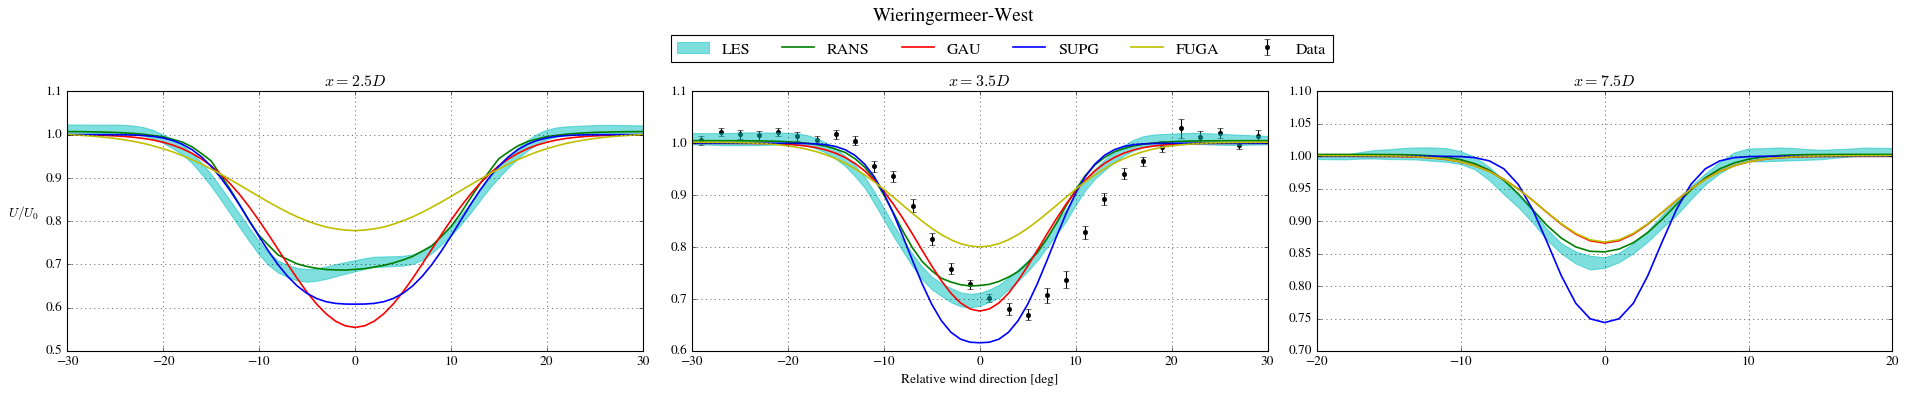

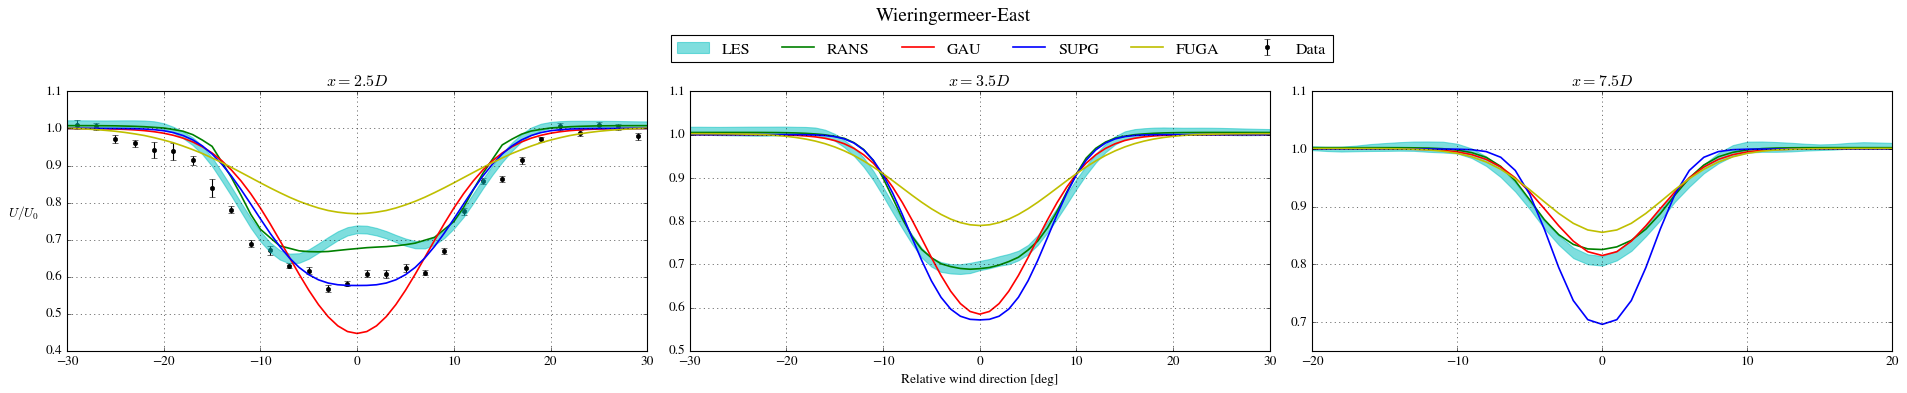

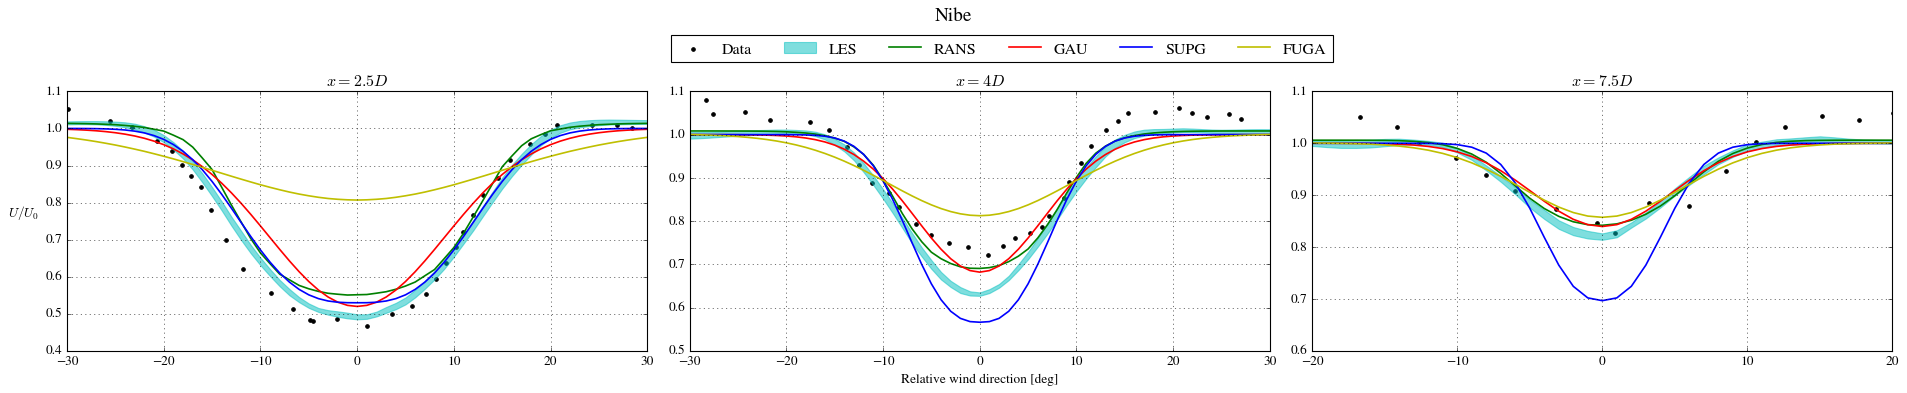

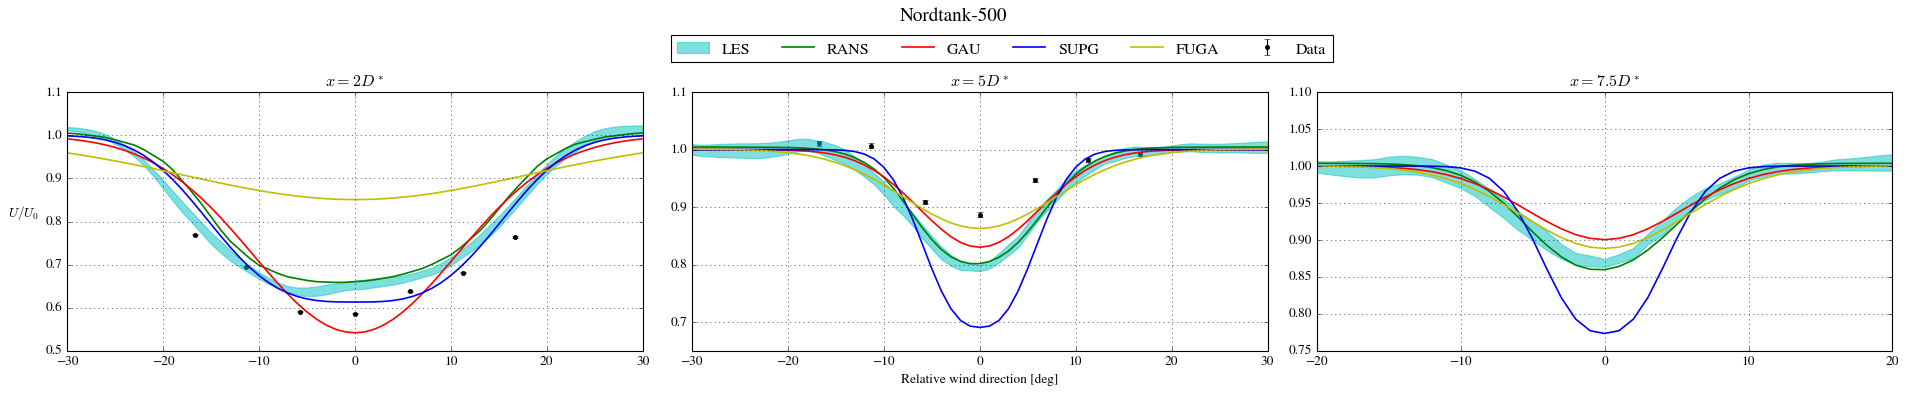

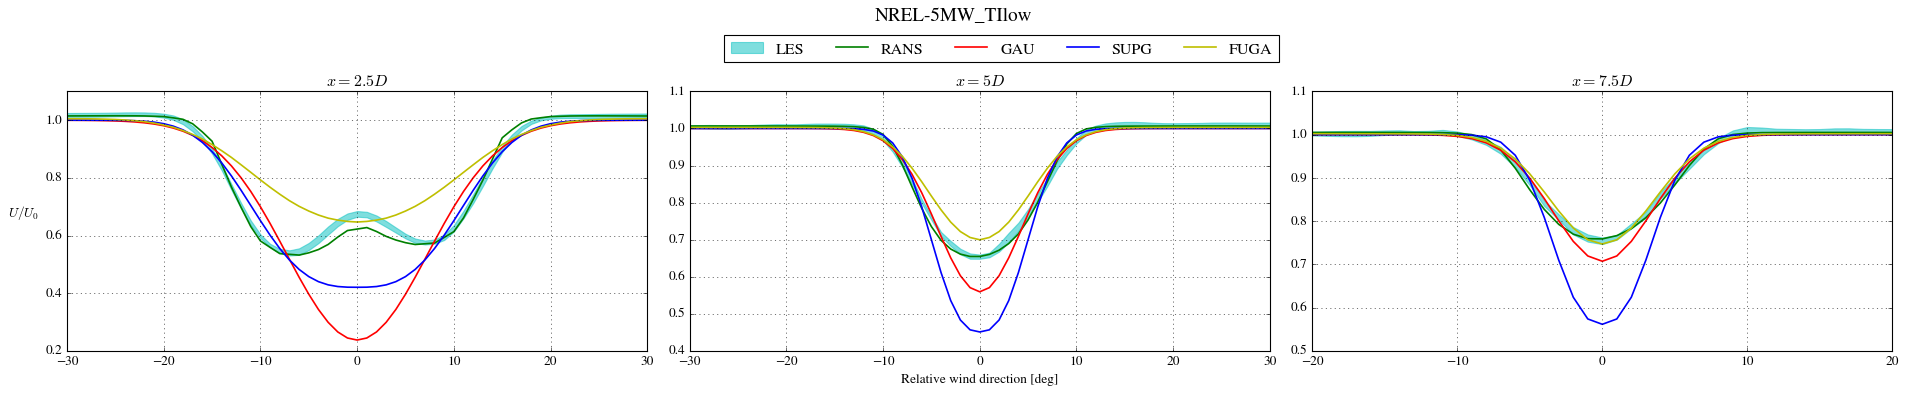

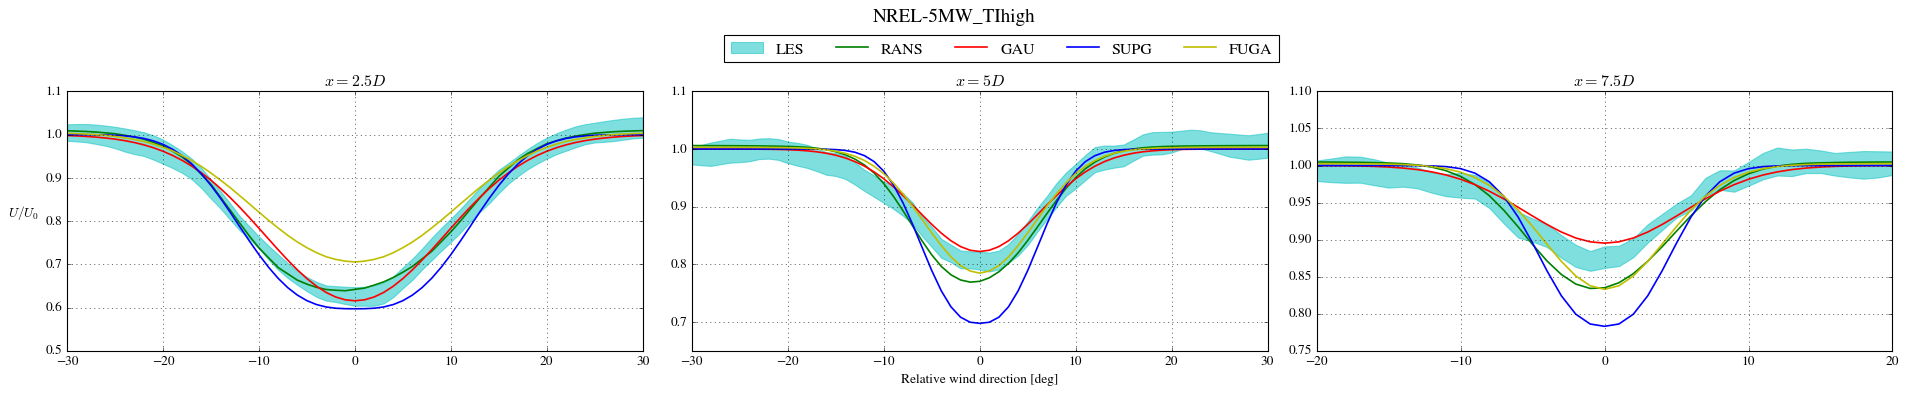

139.8842318058014


In [8]:
# Calling the function to make the plots
import time
tic = time.time()
UdefCases = deficitPlotSingleWakeCases(SingleWakeCases, wffm_list, wm_labels, linewidth, cLES, cRANS, colors)
toc = time.time()
print(toc - tic)

From the previous function, we return the integrated velocity deficit (defined as UdefCases) and plot them as a bar chart to visualize the overall contribution of each model compared to the data and LES and RANS simulations.

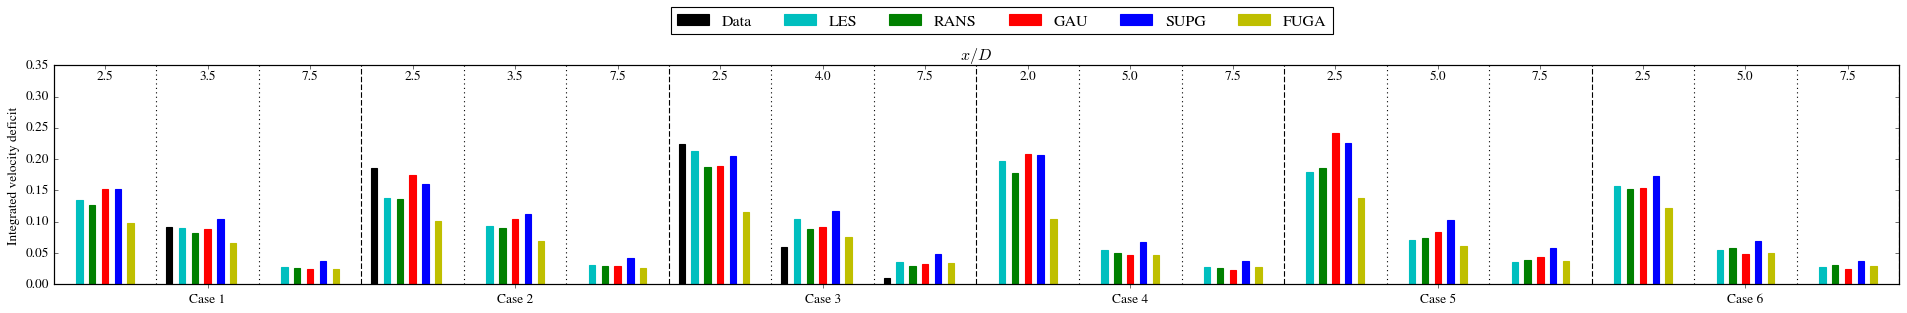

In [9]:
barPlotSingleWakeCases(SingleWakeCases, UdefCases, wm_labels, cLES, cRANS, colors)

## Single Wake Case - SWiFT
---

The SWiFT Single Wake cases studied in the benchmark corresponds to:
    
| Name | $U_0$ (m/s) | $TI$ (%)| $D$ (m)| $z_H$ (m)| 
| :--- | :--- | :--- | :--- | :--- | 
| Neutral | 8.7 | 8.8 | 27 | 32.1
| Stable | 4.8 | 2.9 | 27 | 32.1
| Unstable | 6.7 | 10 | 27 | 32.1

In [10]:
from py_wake.validation.benchmark.single_wake_plot_func import plotSingleWake_SWiFT

In [11]:
# Import path for FUGA LUTs for each case
path_neutral = lut_path + '/SWiFT-Neutral/LUTs_Zeta0=0.00e+00_16_32_D27_zhub32.1_zi400_z0=0.01000000_z32.1_UL_nx2048_ny512_dx6.75_dy1.6875.nc'
path_stable = lut_path + '/SWiFT-Stable/LUTs_Zeta0=2.51e-15_16_32_D27_zhub32.1_zi400_z0=0.00003400_z32.1_UL_nx2048_ny512_dx6.75_dy1.6875.nc'
path_unstable = lut_path + '/SWiFT-Unstable/LUTs_Zeta0=-8.90e-05_16_32_D27_zhub32.1_zi400_z0=0.01000000_z32.1_UL_nx2048_ny512_dx6.75_dy1.6875.nc'

In [12]:
# Defining the dictionary containing all of the cases and their setup

StabilityCases = [
    {'case_name': 'neutral', 'U0': 8.7, 'TI': 0.088, 'fugaPath': path_neutral},
    {'case_name': 'stable', 'U0': 4.8, 'TI': 0.029, 'fugaPath': path_stable},
    {'case_name': 'unstable', 'U0': 6.6, 'TI': 0.1, 'fugaPath': path_unstable}
]

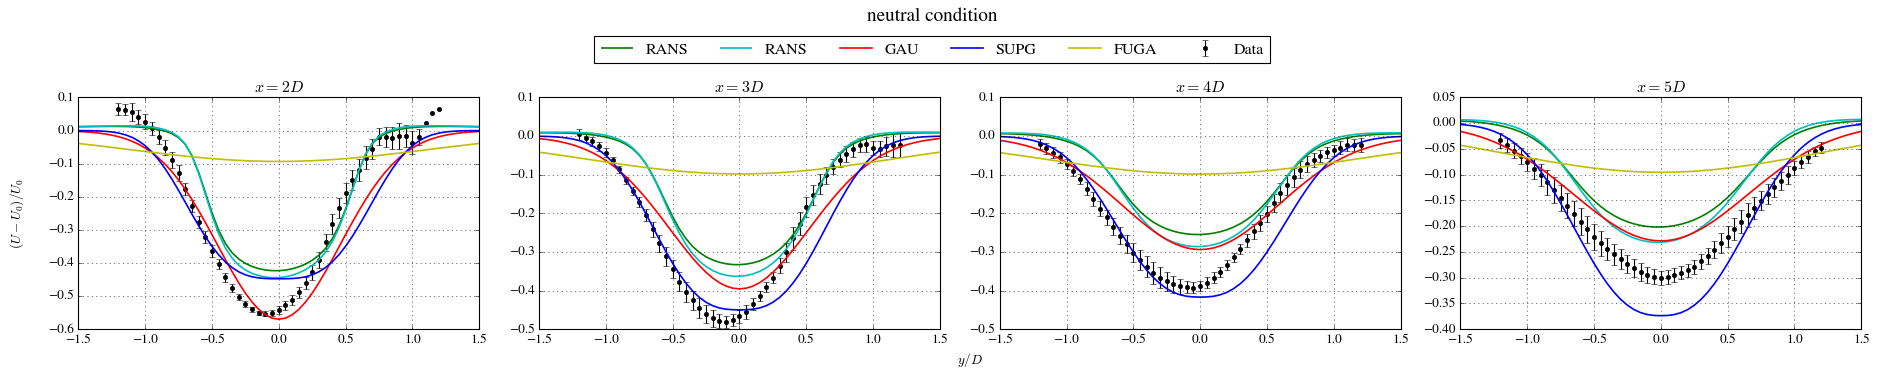

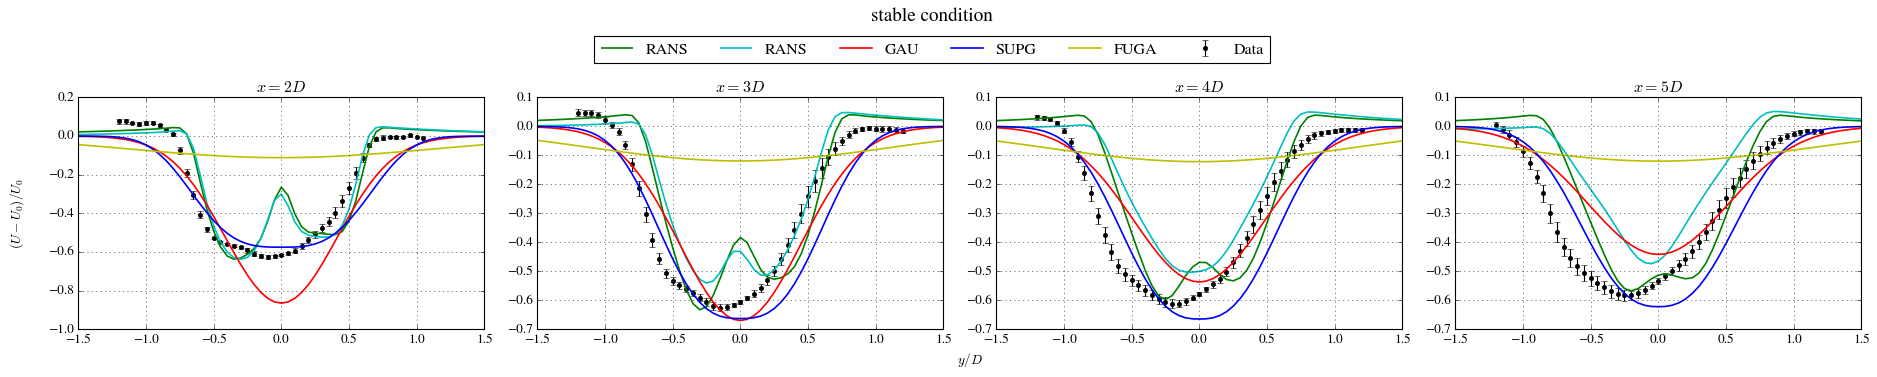

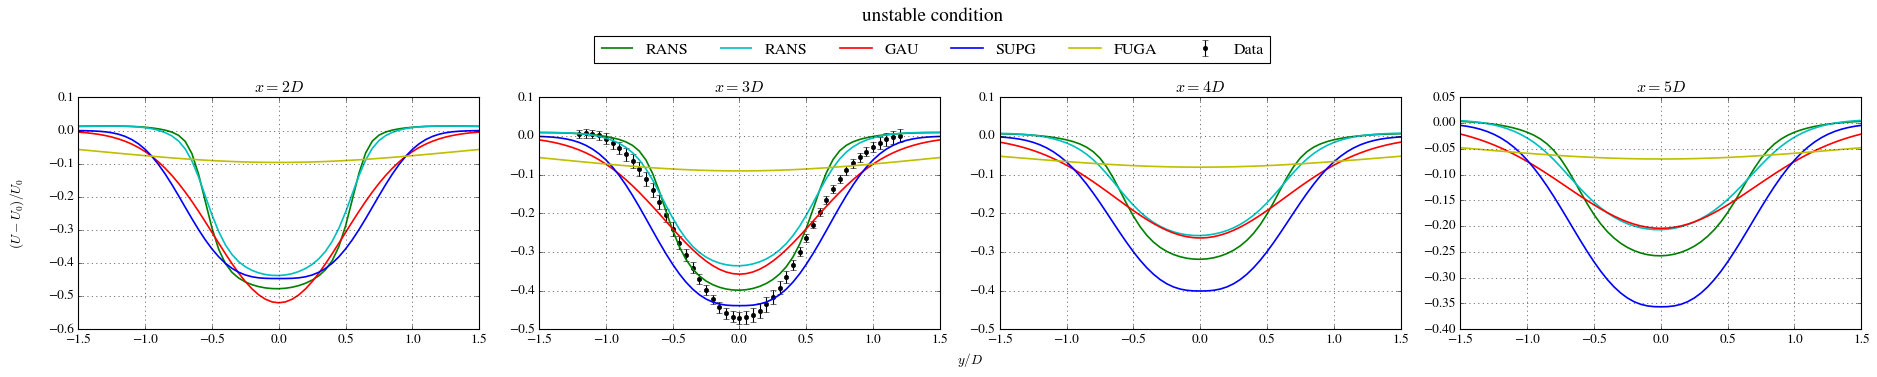

In [13]:
# Calling the function to make the plots

plotSingleWake_SWiFT(StabilityCases, wffm_list, wm_labels, colors, linewidth, cLES)

## Wind Farm Cases
---

The Wind Farm Cases studied in the benchmark correspond to:
    
| Name | $U_0$ (m/s)  | $TI$ (%) | $D$ (m) | $z_H$ (m) |
| :--- | :--- | :--- | :--- | :--- | 
| Wieringermeer | 8.35 | 9.6 | 80 | 80 | 
| Lillgrund | 9.0 | 4.8 | 92.6 | 65 | 
| Horns Rev I | 8.0 | 5.6 | 80 | 70 | 

In [14]:
from py_wake.validation.benchmark.wind_farm_plot_func import deficitPlotWFCases

# PyWake objects for HornsRev
from py_wake.examples.data.hornsrev1 import Hornsrev1Site
from py_wake.site import UniformSite
from py_wake.examples.data.lillgrund import SWT23, LillgrundSite  
from py_wake.examples.data.lillgrund import wt_x as wt_x_l
from py_wake.examples.data.lillgrund import wt_y as wt_y_l
from py_wake.examples.data.ecn_wieringermeer import N80   
from py_wake.examples.data.ecn_wieringermeer import wt_x as wt_x_w
from py_wake.examples.data.ecn_wieringermeer import wt_y as wt_y_w
from py_wake.examples.data.hornsrev1 import HornsrevV80
from py_wake.examples.data.hornsrev1 import wt_x as wt_x_hr
from py_wake.examples.data.hornsrev1 import wt_y as wt_y_hr

# Creating site object for Wieringermeer
site_wiering = UniformSite(p_wd=[1], ti=0.096/0.8, ws=8.35)

# WTs representing the inner rows of Horns Rev 1
hr_inner_rows = np.linspace(0, 79, 80).reshape(10, 8)[:, 1:7].flatten(
).tolist() 

In [15]:
# Import path for FUGA LUTs for each case

path_wieringermeer = lut_path + '/Wieringermeer_WF/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00239000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_lillgrund = lut_path + '/Lillgrund_WF/LUTs_Zeta0=0.00e+00_8_32_D92.6_zhub65_zi400_z0=0.00005000_z65.0_UL_nx2048_ny512_dx23.15_dy5.7875.nc'
path_hornsrev = lut_path + '/Hornsrev_WF/LUTs_Zeta0=0.00e+00_8_32_D80_zhub70_zi400_z0=0.00000100_z70.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'

In [16]:
# Defining the dictionary containing all of the cases and their setup

WFcases = [{'name': 'Wieringermeer', 'U0': 8.35, 'TItot': 0.096, 'wt': N80(), 'wt_x': wt_x_w, 'wt_y': wt_y_w, 'site': site_wiering, 'location': 'onshore',
                    'plots': [{'name': 'Row', 'wd': 275.0, 'wts': [0, 1, 2, 3, 4]}], 'fugaPath': path_wieringermeer},
           {'name': 'Lillgrund', 'U0': 9.0, 'TItot': 0.048, 'wt': SWT23(), 'wt_x': wt_x_l, 'wt_y': wt_y_l, 'site': LillgrundSite(), 'location': 'offshore',
                    'plots': [{'name': 'RowB', 'wd': 222.0, 'wts': [14, 13, 12, 11, 10, 9, 8, 7]},
                              {'name': 'RowD', 'wd': 222.0, 'wts': [29, 28, 27, np.nan, 26, 25, 24, 23]},
                              {'name': 'RowB', 'wd': 207.0, 'wts': [14, 13, 12, 11, 10, 9, 8, 7]},
                              {'name': 'RowD', 'wd': 207.0, 'wts': [29, 28, 27, np.nan, 26, 25, 24, 23]},
                              {'name': 'Row6', 'wd': 120.0, 'wts': [2, 9, 17, 25, 32, 37, 42, 46]},
                              {'name': 'Row4', 'wd': 120.0, 'wts': [4, 11, 19, np.nan, np.nan, 39, 44]},
                              {'name': 'Row6', 'wd': 105.0, 'wts': [2, 9, 17, 25, 32, 37, 42, 46]},
                              {'name': 'Row4', 'wd': 105.0, 'wts': [4, 11, 19, np.nan, np.nan, 39, 44]},
                              {'name': 'WFeff'}], 'fugaPath': path_lillgrund},
           {'name': 'Hornsrev1', 'U0': 8.0, 'TItot': 0.056, 'wt': HornsrevV80(), 'wt_x': wt_x_hr, 'wt_y': wt_y_hr, 'site': Hornsrev1Site(), 'location': 'offshore',
                    'plots': [{'name': 'InnerRowMean', 'wd': 270.0, 'wts': hr_inner_rows}], 'fugaPath': path_hornsrev}
           ]

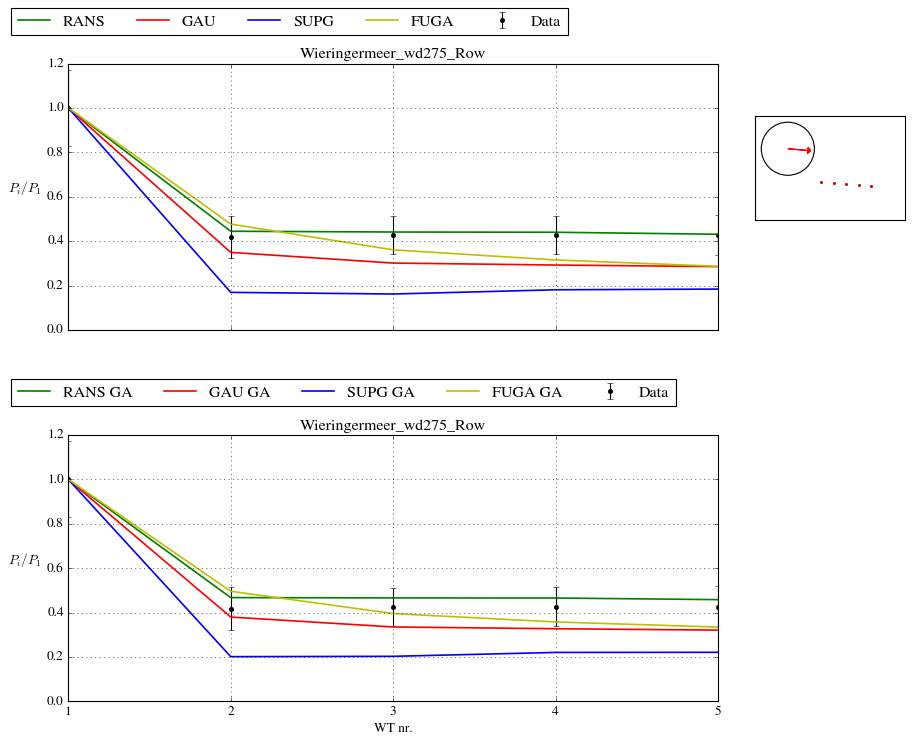

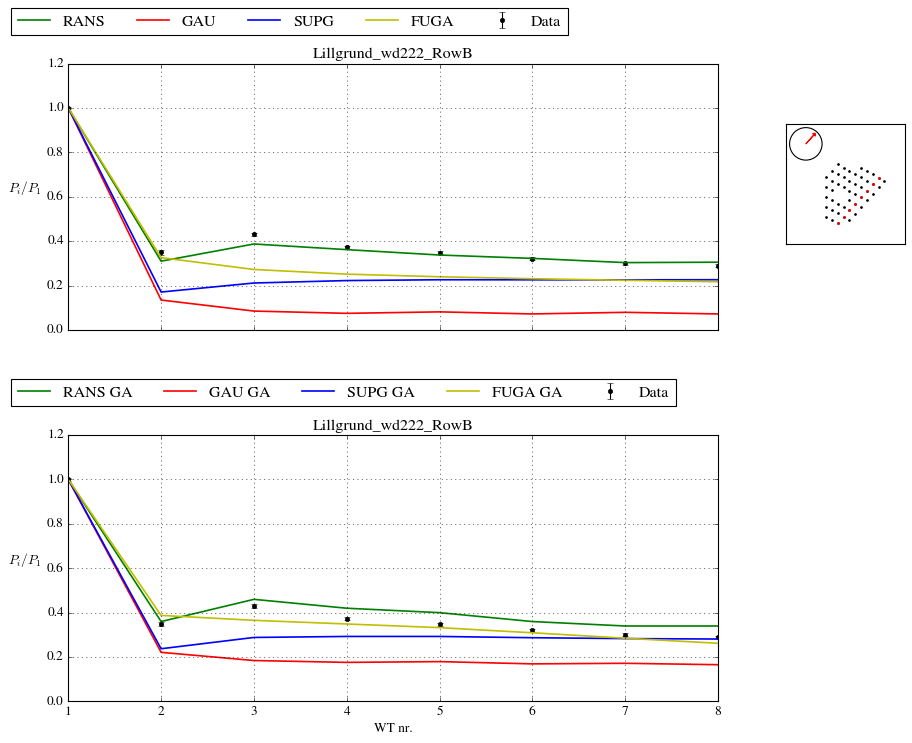

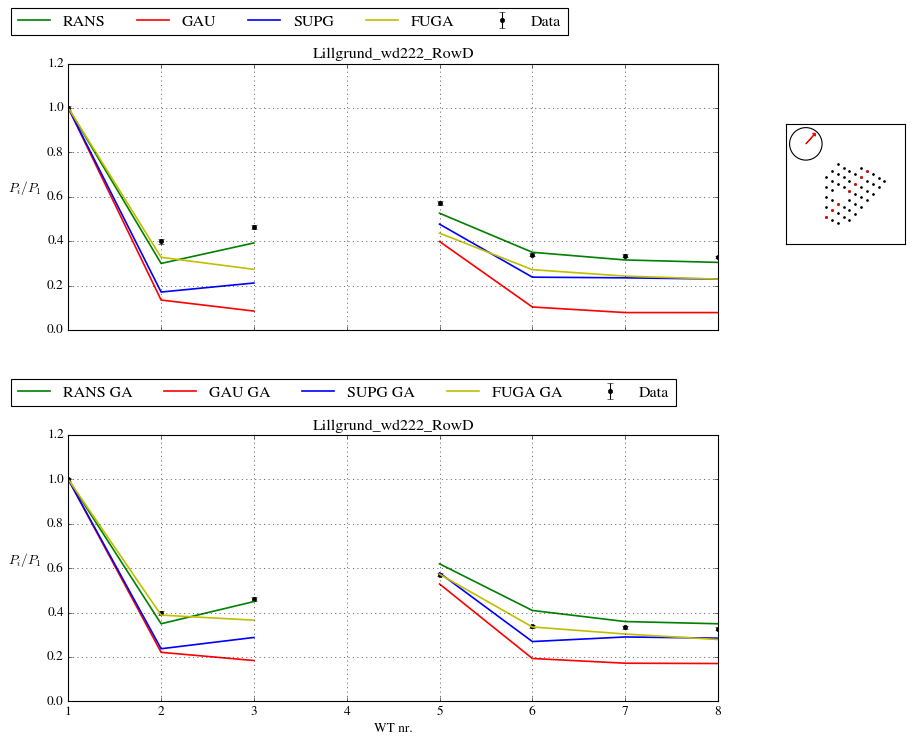

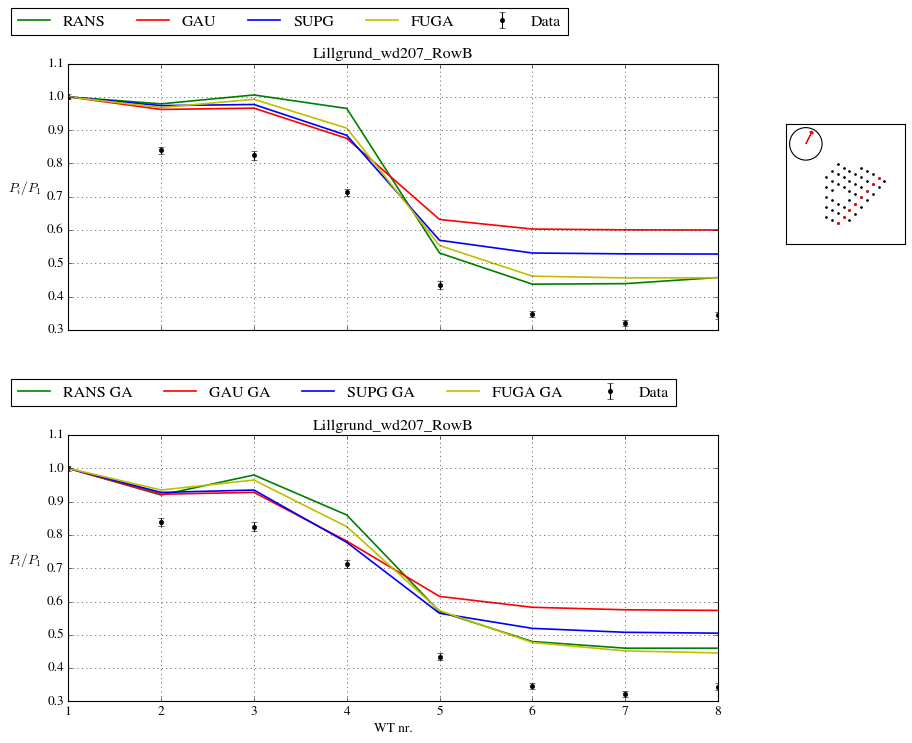

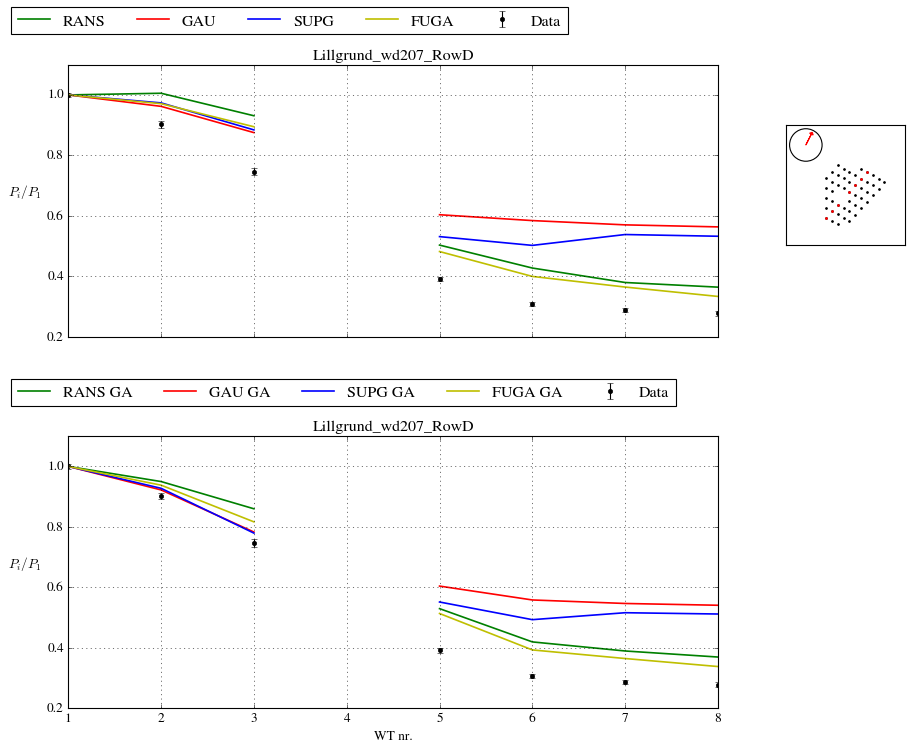

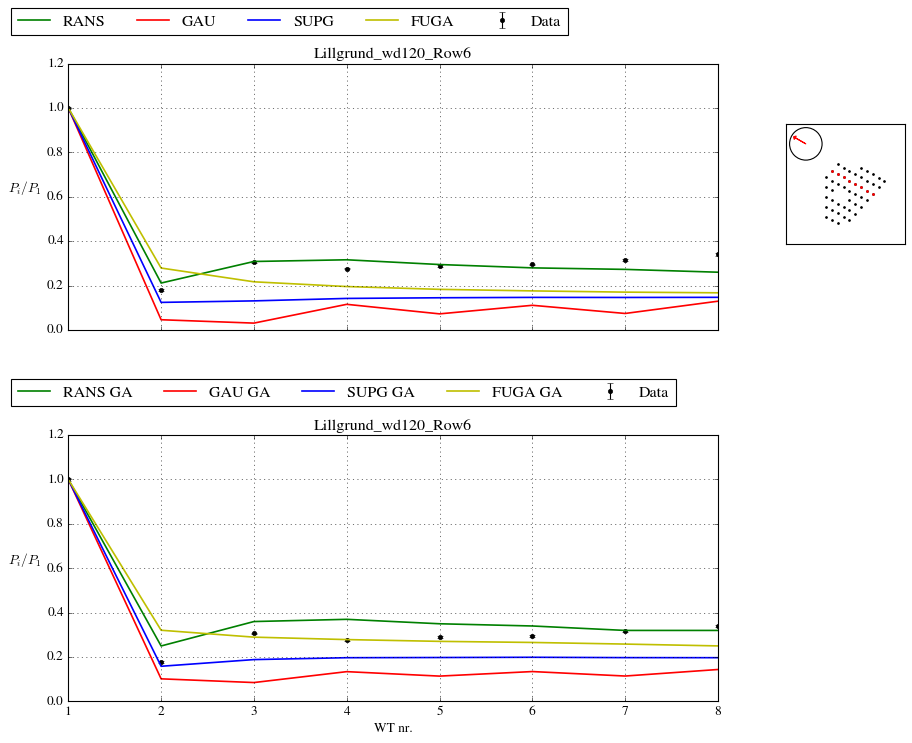

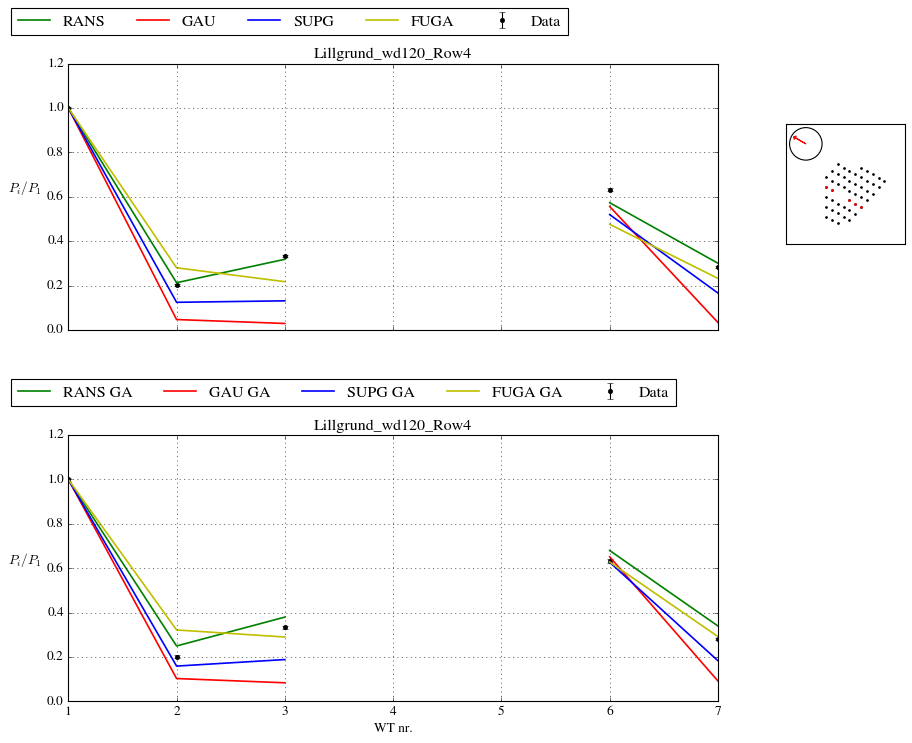

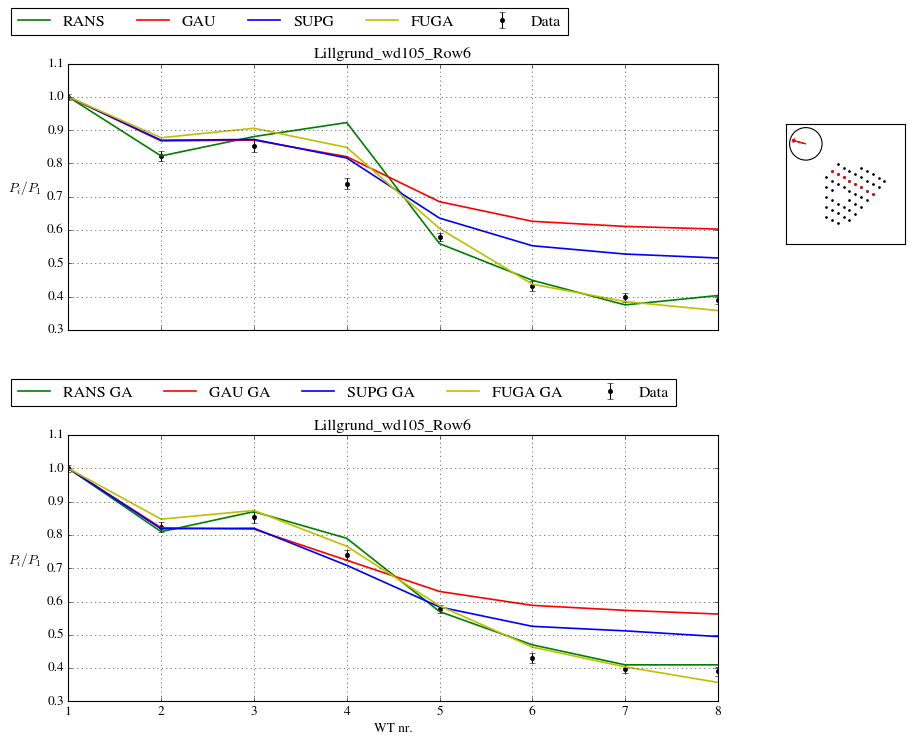

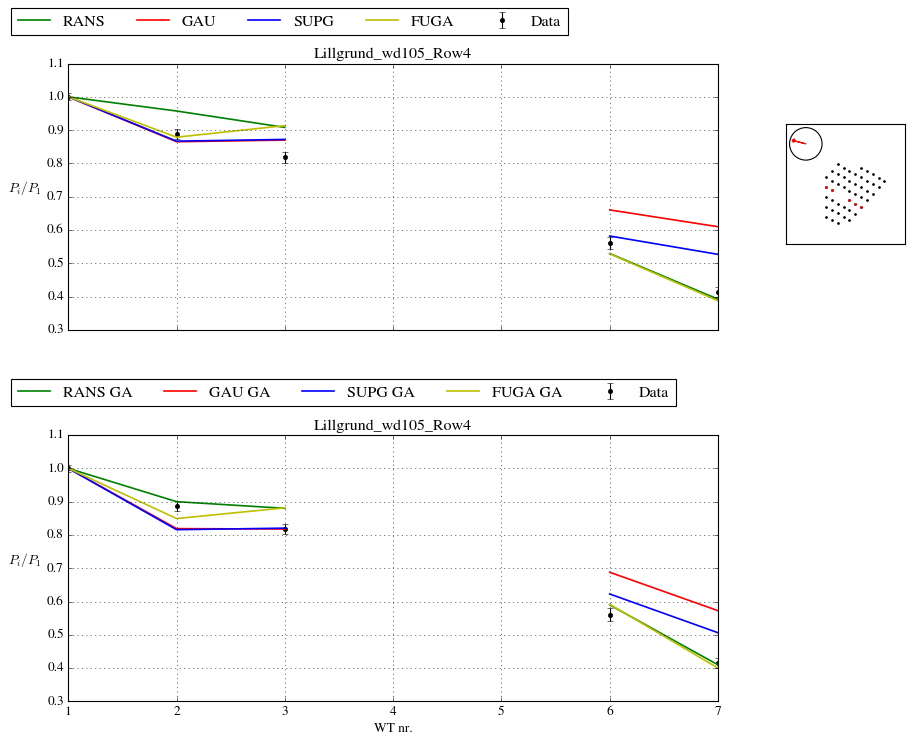

WFeff GAU 0.6425594927379984
WFeff SUPG 0.643257701458463
WFeff FUGA 0.6668497169469709
WFeff RANS 0.6393736000000001
WFeff DATA 0.6592924166666666


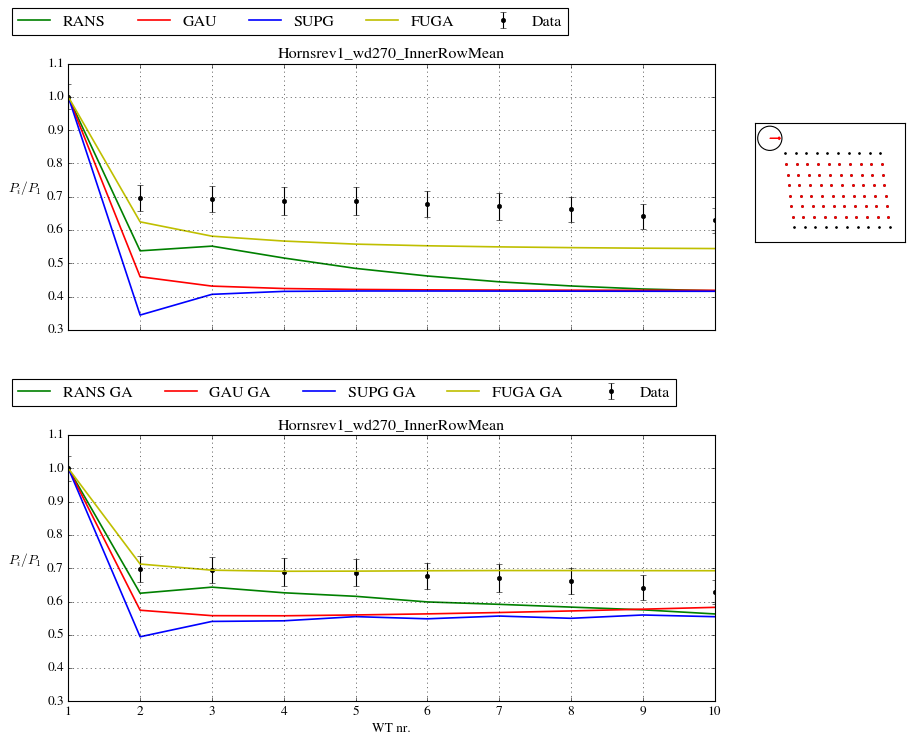

In [17]:
# Calling the function to make the plots

deficitPlotWFCases(WFcases, wffm_list, wm_labels, linewidth, cLES, cRANS, colors)

## Farm to Farm Interaction
---

In [ ]:
from py_wake.validation.benchmark.f2f_plot_func import plotF2FCase

Nysted, Rødsand II, SCADA data, diameter used as references corresponds to  Rødsand II's wind turbine, $D = 93 m $.

| Name | $U_0$ (m/s)  | $TI$ (%) | $z_H$ (m) |
| :--- | :--- | :--- | :--- |  
| Nysted + Rødsand | 8 | 7 | 68.5 | 

In [ ]:
# Calling the function to make the plots

plotF2FCase(wffm_list, wm_labels, linewidth, cRANS, colors, plotGAonly=False)